# Package imports

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.optimize import LinearConstraint
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt

In [2]:
def model(t, x, p):
    S, I, R = x
    β, γ, ν = p

    dS_dt = ν*R - β*S*I
    dI_dt = β*S*I - γ*I
    dR_dt = γ*I - ν*R

    return np.array([dS_dt, dI_dt, dR_dt])

### Simulate ODE Trajectory

In [3]:
β = 1.5
γ = 1
ν = 1/12

p = (β, γ, ν)

tmax = 21
tspan = (0, tmax)
num_observations = 32
obs_times = np.linspace(tspan[0], tspan[1], num_observations)
i0 = 1e-3
x0 = (1 - i0, i0, 0)
parameterized_model = lambda t, x: model(t, x, p)
sol = solve_ivp(parameterized_model, tspan, x0, method='RK45', t_eval=obs_times)

### Add multiplicative noise

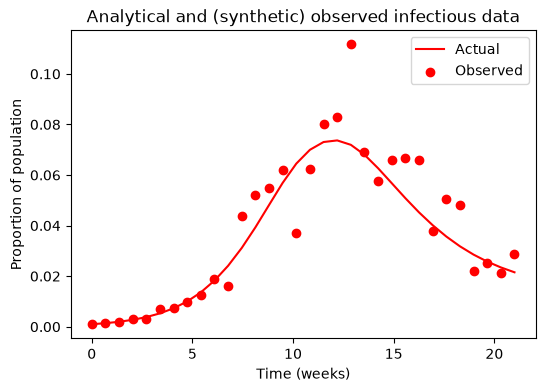

In [4]:
std_dev = 0.25 # 10% noise

observations = sol.y[1]*np.exp(np.random.normal(0, std_dev, num_observations))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")

ax.legend()
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Proportion of population")

plt.title("Analytical and (synthetic) observed infectious data")

plt.savefig("Figures/SIRS_actual_vs_observed_data.pdf", dpi=300)

plt.show()

In [5]:
# Calculates the L2 log difference between two arrays
def log_loss_functional(arr1, arr2):
    # Ensure that arr1 and arr2 have the same shape
    if np.shape(arr1) != np.shape(arr2):
        print("Error in loss_functional: arr1 and arr2 must have same shape")
        return -1

    # Convert arrays to numpy arrays if necessary
    if not isinstance(arr1, np.ndarray):
        arr1 = np.array(arr1)
    if not isinstance(arr2, np.ndarray):
        arr2 = np.array(arr2)

    # Ensure that arr1 is nonnegative and arr2 is positive
    arr1 = np.where(arr1 > 0, arr1, 0)
    arr2 = np.where(arr2 > 0, arr2, 1e-32)

    # Calculate arr1 / arr2 elementwise, ensuring all results are positive
    arr1_over_arr2_positive = np.where(arr1 / arr2 > 0, arr1 / arr2, 1e-32) 
    
    # Return the sum-of-squared log distances between arr1 and arr2
    return np.sum(np.pow(np.log(arr1_over_arr2_positive), 2))




# # Calculates the L2 log difference between two arrays
# def linear_loss_functional(arr1, arr2):
#     # Ensure that arr1 and arr2 have the same shape
#     if np.shape(arr1) != np.shape(arr2):
#         print("Error in loss_functional: arr1 and arr2 must have same shape")
#         return -1
#
#     # Convert arrays to numpy arrays if necessary
#     if not isinstance(arr1, np.ndarray):
#         arr1 = np.array(arr1)
#     if not isinstance(arr2, np.ndarray):
#         arr2 = np.array(arr2)
#
#     # Return the sum-of-squared log distances between arr1 and arr2
#     return np.sum(np.pow(arr1 - arr2, 2))




# Calculates the L2 difference between observations and the model with parameters p
def calculate_model_loss(obs_times, observations, model, x0, p, observed_variables=None):
    cumulative_loss = 0

    # If observed variables are not given, return
    if observed_variables is None:
        print("Error: the indices of the observed components must be provided.")
        return -1

    observations = np.array(observations)
    observed_variables = np.array(observed_variables)

    # If observations is a 1D array, turn it into a 2D array with one row
    if observations.ndim == 1:
        observations = observations.reshape(1, -1)

    if observed_variables.ndim != 2:
        print(f"Error: observed_variables must have two dimensions. observed_variables.ndim = {observed_variables.ndim}")
        return -1

    if observed_variables.shape[0] != observations.shape[0]:
        print("Error: the number of observed variables must match the number of rows in observations")
        print(f"observed_variables.shape[0] = {observed_variables.shape[0]}")
        print(f"observations.shape[0] = {observations.shape[0]}")
        return -1

    parameterized_model = lambda t, x: model(t, x, p)
    tspan = (obs_times[0], obs_times[-1])
    sol = solve_ivp(parameterized_model, tspan, x0, method='RK45', t_eval=obs_times)

    # print([sol.y[i] for i in observed_variables])
    # print(np.array([sol.y[i] for i in observed_variables]))
    # print(np.sum(np.array([sol.y[i] for i in observed_variables]), axis=0))

    for i in range(observed_variables.shape[0]):
        cumulative_loss += log_loss_functional(observations[i], np.sum(np.array([sol.y[j] for j in observed_variables[i]]), axis=0))

    return cumulative_loss




def generate_known_vars_constraint(nvars, known_vars, wiggle_room=0):
    # Don't create a linear constraint if no variables are known
    if known_vars is None:
        return None

    # Ensure that length(known_vars) is equal to the number of variables
    if len(known_vars) != nvars:
        print("Error: length(known_vars) is not equal to the number of variables, defaulting to known_vars = None.")
        return None

    # Find the indices of known variables
    known_var_indices = np.where(np.array(known_vars) != None)[0]

    # If known_vars only contains None, then no variables are known
    if known_var_indices.size == 0:
        return None
    
    # Now known_p contains at least one known parameter, so create the constraint
    constraint_matrix = np.zeros((len(known_var_indices), nvars))
    for i in range(len(known_var_indices)):
        constraint_matrix[i, known_var_indices[i]] = 1

    constraint_values = np.array([known_vars[known_var_indices[i]] for i in range(len(known_var_indices))])
    return LinearConstraint(constraint_matrix, constraint_values*(1 - wiggle_room), constraint_values*(1 + wiggle_room))




# # Optimizes the parameters for <model> given an initial condition <x0>, <obs_times>, and <observations>
# def optimize_parameters(obs_times, observations, model, x0, p_guess, known_p=None, p_bounds=None, tol=1e-8, wiggle_room=1e-8):
#     npars = len(p_guess)
#     known_p_constraint = None # Set by default, will change if known_p is given
#
#     # Set parameter bounds to be large if not given
#     if p_bounds == None:
#         p_bounds = [(0, 1e4) for i in range(npars)]
#
#     known_p_constraint = generate_known_vars_constraint(npars, known_p, wiggle_room=wiggle_room)
#
#     npars = len(p_guess) # Number of parameters
#     initial_guess = p_guess # Initial parameter guess
#     objfun = lambda p: calculate_model_loss(obs_times, observations, model, x0, p) # Objective function
#
#     # Find optimal parameters
#     return minimize(objfun, initial_guess, bounds=p_bounds, tol=tol, constraints=(known_p_constraint))




def optimize_parameters(obs_times, observations, model, x0, p_guess, **kwargs):
    observed_variables = kwargs.get("observed_variables", None)
    known_p = kwargs.get("known_p", None)
    p_bounds = kwargs.get("p_bounds", None)
    tol = kwargs.get("tol", 1e-8)
    wiggle_room = kwargs.get("wiggle_room", 1e-8)

    # Call optimize_ics_and_parameters with x0_guess and known_x0 fixed as x0
    return optimize_ics_and_parameters(obs_times, observations, model, x0, p_guess, observed_variables=observed_variables,
            known_x0=x0, known_p=known_p, x0_bounds=None, p_bounds=p_bounds, tol=tol, wiggle_room=0)





# Optimizes the parameters and initial conditions for <model> given <obs_times> and <observations>
def optimize_ics_and_parameters(obs_times, observations, model, x0_guess, p_guess, **kwargs):
    observed_variables = kwargs.get("observed_variables", None)
    known_x0 = kwargs.get("known_x0", None)
    known_p = kwargs.get("known_p", None)
    x0_bounds = kwargs.get("x0_bounds", None)
    p_bounds = kwargs.get("p_bounds", None)
    tol = kwargs.get("tol", 1e-8)
    wiggle_room = kwargs.get("wiggle_room", 1e-12)

    if observed_variables is None:
        print("Error: indeces of observed variables must be provided")
        return -1

    nstates = len(x0_guess) # Number of state variables
    npars = len(p_guess) # Number of parameters
    constraints = []

    # If known_x0 or known_p are none, reallocate them as arrays with entries <None>
    if known_x0 is None:
        known_x0 = np.empty((nstates), dtype=object)
    if known_p is None:
        known_p = np.empty((npars), dtype=object)

    # Set x0 and parameter bounds to [0, Inf) if not given
    if x0_bounds is None:
        x0_bounds = [(0, None) for i in range(nstates)]
    if p_bounds is None:
        p_bounds = [(0, None) for i in range(npars)]

    # Generate the x0 and p constraints from the provided known values
    known_x0_constraint = generate_known_vars_constraint(nstates, known_x0, wiggle_room=wiggle_room)
    known_p_constraint = generate_known_vars_constraint(npars, known_p, wiggle_room=wiggle_room)

    # Extend the size of the x0 constraint to include p variables
    if known_x0_constraint != None:
        known_x0 = np.array(known_x0)
        A = known_x0_constraint.A
        A = np.hstack((A, np.zeros((A.shape[0], npars))))
        lb = known_x0_constraint.lb
        ub = known_x0_constraint.ub
        constraints.append(LinearConstraint(A, lb, ub))
        x0_guess = np.where(known_x0 != None, known_x0, x0_guess) # Replace guesses with known values

    # Extend the size of the p constraint to include x0 variables
    if known_p_constraint != None:
        known_p = np.array(known_p)
        A = known_p_constraint.A
        A = np.hstack((np.zeros((A.shape[0], nstates)), A))
        lb = known_p_constraint.lb
        ub = known_p_constraint.ub
        constraints.append(LinearConstraint(A, lb, ub))
        p_guess = np.where(known_p != None, known_p, p_guess) # Replace guesses with known values

    # If not all x0 components are known, add a constraint so that the initial pop. size is the same as that guessed
    if known_x0 is None or np.any(known_x0 == None):
        constraint_matrix = np.concatenate((np.ones(nstates), np.zeros(npars))) # e.g. [1 1 1 0 0 0]
        const_pop_size_constraint = LinearConstraint(constraint_matrix, sum(x0_guess)*(1 - wiggle_room), sum(x0_guess)*(1 + wiggle_room))
        constraints.append(const_pop_size_constraint)

    # Define the objective function to optimize the vector u = [<x0>, <p>]
    objfun = lambda u: calculate_model_loss(obs_times, observations, model, u[:nstates], u[nstates:], observed_variables=observed_variables)
    
    # Define initial guess and bounds using x0 and p
    initial_guess = np.concatenate((x0_guess, p_guess))
    bounds = np.concatenate((x0_bounds, p_bounds))

    return minimize(objfun, initial_guess, bounds=bounds, constraints=constraints, tol=tol)
    # return minimize(objfun, initial_guess, bounds=bounds, constraints=(const_pop_size_constraint, known_x0_constraint), tol=tol)

### Testing parameter optimization with known IC

Optimal parameters: [1.4 , 0.91, 0.07]


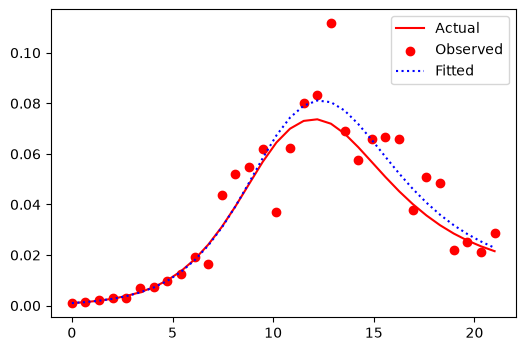

In [8]:
p_bounds = [(1e-6, 25), (1e-6, 5), (1e-6, 50)]

# Find optimal parameters
optimal_result = optimize_parameters(obs_times, observations, model, x0, observed_variables=[[1]], p_guess=(2.5, 1, 1/12), known_p=None, p_bounds=p_bounds, tol=1e-12)

#optimal_p = optimal_result.x
optimal_p = optimal_result.x[3:]

print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

# Simulate model with optimal parameters
optimal_model = lambda t, x: model(t, x, optimal_p)
optimal_sol = solve_ivp(optimal_model, tspan, x0, method='RK45', t_eval=obs_times)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")
ax.plot(obs_times, optimal_sol.y[1], color='blue', linestyle=":", label="Fitted")

ax.legend()

plt.show()

### Testing parameter and IC optimization

Optimal ICs: [9.9899e-01, 1.0052e-03, 1.7854e-11]
Optimal parameters: [1.4 , 0.91, 0.07]


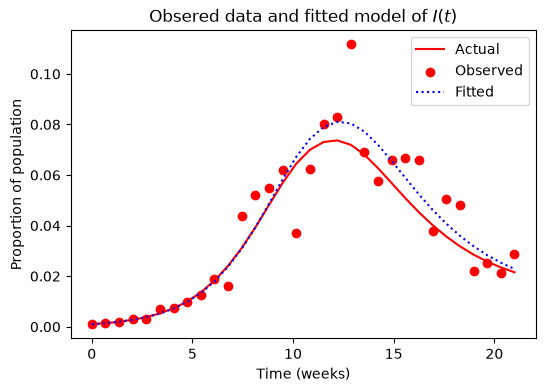

In [10]:
x0_bounds = [(0, 1), (0, 1), (0, 0.1)]

# Find optimal parameters and ICs
optimal_result = optimize_ics_and_parameters(obs_times, observations, model,
        observed_variables=[[1]],
        x0_guess=(1 - 10*i0, 10*i0, 0), 
        p_guess=(10, 0.5, 1/6), 
        known_x0=None, known_p=None,
        x0_bounds=x0_bounds, p_bounds=p_bounds, 
        tol=1e-12,
        wiggle_room=1e-8,
)

optimal_x0 = optimal_result.x[:3]
optimal_p = optimal_result.x[3:]

print("Optimal ICs: " + np.array2string(optimal_x0, precision=4, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

# Simulate model with optimal parameters
optimal_model = lambda t, x: model(t, x, optimal_p)
optimal_sol = solve_ivp(optimal_model, tspan, optimal_x0, method='RK45', t_eval=obs_times)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")
ax.plot(obs_times, optimal_sol.y[1], color='blue', linestyle=":", label="Fitted")

ax.legend()
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Proportion of population")

plt.title("Obsered data and fitted model of $I(t)$")

plt.savefig("Figures/SIRS_fitted.pdf", dpi=300)

plt.show()

### Fix all parameters except $\beta$, randomly sample $\beta$ and obtain a distribution of optimal $\beta$ values.

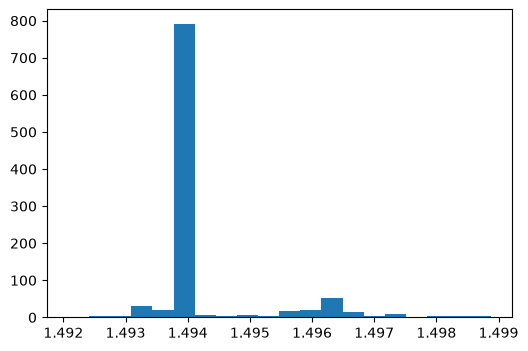

In [12]:
num_samples = 1000
beta_range = (0.1, 10)
beta_samples = np.random.uniform(low=beta_range[0], high=beta_range[1], size=num_samples)
optimal_betas = np.zeros((num_samples))

for i, beta in enumerate(beta_samples):
    optimal_result = optimize_parameters(obs_times, observations, model, x0, 
            observed_variables=[[1]],
            p_guess=(beta, 1, 1/12), known_p=(None, 1, 1/12), 
            p_bounds=((0.5, 2.5), (0, 10), (0, 10)), tol=1e-2)
    optimal_betas[i] = optimal_result.x[3]

fig = plt.figure(figsize=(6, 4))

plt.hist(optimal_betas, bins=20)

plt.show()

# Testing model fitting on 1978 English Boarding School Influenza data

Optimal x0: [1., 0., 0.]
Optimal parameters: [1.55e+00, 3.45e-01, 1.00e-06]
R0 = 4.50


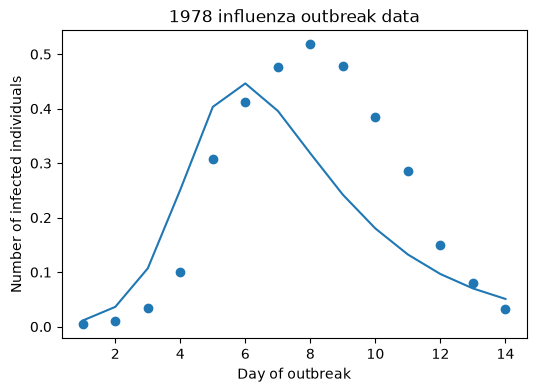

In [14]:
year = 1978
N = 763
observation_days = np.arange(1, 15)
dates = np.array([f"01-{day}" for day in range(22, 32)])
dates = np.concatenate((dates, np.array([f"02-0{day}" for day in range(1, 5)])))

in_bed = np.array([3, 8, 26, 76, 225, 298, 258, 233, 189, 128, 68, 29, 14, 4])
convalescent = np.array([0, 0, 0, 0, 9, 17, 105, 162, 176, 166, 150, 85, 47, 20])
infected = (in_bed + convalescent) / N

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(np.arange(1, 15), infected)
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")

ax.set_title("1978 influenza outbreak data")

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, model,
        observed_variables=[[1]],
        x0_guess=(N - I0_guess, I0_guess, 0), 
        p_guess=(2.5, 0.1, 0), 
        known_x0=(None, None, 0), known_p=None,
        x0_bounds=x0_bounds, p_bounds=p_bounds, 
        tol=1e-8,
        wiggle_room=1e-12,
)

optimal_x0 = optimal_result.x[:3]
optimal_p = optimal_result.x[3:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: model(t, x, optimal_p), (0, 14), optimal_x0, method='RK45', t_eval=observation_days)

ax.plot(observation_days, optimal_sol.y[1])

print(f"R0 = {(optimal_p[0] / optimal_p[1]):.2f}")

### What if we add extra days of zeros?

24
24
Optimal x0: [1., 0., 0.]
Optimal parameters: [1.55e+00, 3.45e-01, 1.00e-06]
R0 = 4.50


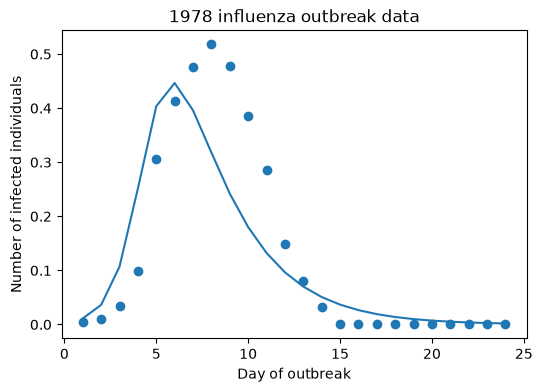

In [15]:
num_extra_days = 10
observation_days = np.arange(1, 15 + num_extra_days)
dates = np.array([f"01-{day}" for day in range(22, 32)])
dates = np.concatenate((dates, np.array([f"02-0{day}" for day in range(1, 5)])))

in_bed = np.array([3, 8, 26, 76, 225, 298, 258, 233, 189, 128, 68, 29, 14, 4])
convalescent = np.array([0, 0, 0, 0, 9, 17, 105, 162, 176, 166, 150, 85, 47, 20])
infected = (in_bed + convalescent) / N

infected = np.concatenate((infected, np.zeros((num_extra_days))))

print(len(observation_days))
print(len(infected))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(observation_days, infected)
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")

ax.set_title("1978 influenza outbreak data")

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, model,
        observed_variables=[[1]],
        x0_guess=(N - I0_guess, I0_guess, 0), 
        p_guess=(2.5, 0.1, 0), 
        known_x0=(None, None, 0), known_p=None,
        x0_bounds=x0_bounds, p_bounds=p_bounds, 
        tol=1e-8,
        wiggle_room=1e-12,
)

optimal_x0 = optimal_result.x[:3]
optimal_p = optimal_result.x[3:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: model(t, x, optimal_p), (0, observation_days[-1]), optimal_x0, method='RK45', t_eval=observation_days)

ax.plot(observation_days, optimal_sol.y[1])

print(f"R0 = {(optimal_p[0] / optimal_p[1]):.2f}")

### What if we have two infectious classes?

Optimal x0: [1.00e+00, 7.11e-10, 9.48e-03, 1.00e-01]
Optimal parameters: [1.42, 0.39, 2.78]
R0 = 0.51


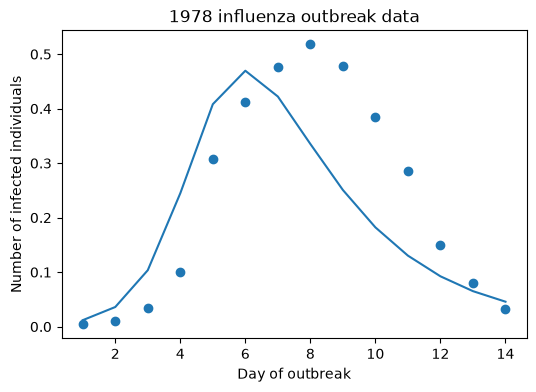

In [20]:
def SEIR_model(t, x, p):
    S, I1, I2, R = x
    β, α, γ = p

    dS_dt = -β*S*(I1 + I2)
    dI1_dt = β*S*(I1 + I2) - α*I1
    dI2_dt = α*I1 - γ*I2
    dR_dt = γ*I2

    return [dS_dt, dI1_dt, dI2_dt, dR_dt]

observation_days = np.arange(1, 15)
dates = np.array([f"01-{day}" for day in range(22, 32)])
dates = np.concatenate((dates, np.array([f"02-0{day}" for day in range(1, 5)])))

in_bed = np.array([3, 8, 26, 76, 225, 298, 258, 233, 189, 128, 68, 29, 14, 4])
convalescent = np.array([0, 0, 0, 0, 9, 17, 105, 162, 176, 166, 150, 85, 47, 20])
infected = (in_bed + convalescent) / N

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(observation_days, infected)
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")

ax.set_title("1978 influenza outbreak data")

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, SEIR_model,
        observed_variables = [[1, 2]],
        x0_guess=(N - I0_guess, 0, I0_guess, 0), 
        p_guess=(1, 0.2, 0.2), 
        known_x0=None, known_p=None,
        x0_bounds=((0, 1), (0, 1), (0, 1e-1), (0, 1e-1)), p_bounds=((0, 50), (1e-2, 1e2), (1e-2, 1e2)), 
        tol=1e-8,
        wiggle_room=1e-8,
)

# optimal_result = optimize_parameters(observation_days, infected, SEIR_model, x0=(1 - I0_guess, 0, I0_guess, 0),
#         observed_variables = [2],
#         p_guess=(1, 1, 1, 1e-1), 
#         known_p=None,
#         p_bounds=((0, 50), (1e-2, 1e1), (1e-2, 1e2), (1e-6, 1)), 
#         tol=1e-8,
#         wiggle_room=1e-8,
# )
#
optimal_x0 = optimal_result.x[:4]
optimal_p = optimal_result.x[4:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: SEIR_model(t, x, optimal_p), (0, observation_days[-1]), optimal_x0, method='RK45', t_eval=observation_days)
# my_sol = solve_ivp(lambda t, x: SEIR_model(t, x, (3, 1, 0.1, 0)), (0, observation_days[-1]), optimal_x0, method='RK45', t_eval=observation_days)

ax.plot(observation_days, optimal_sol.y[1] + optimal_sol.y[2], label="Optimal solution")
# ax.plot(observation_days, my_sol.y[2], label="Guessed solution")

print(f"R0 = {(optimal_p[0] / optimal_p[2]):.2f}")